# Forecasting Ontario's electricity demand with a regression and SARIMA errors

*From a plain regression to a day-ahead forecast that halves the error of "same hour yesterday", one decision at a time: what each step bought, and what the tests said.*

In the [previous post](https://archibaldchain.github.io/articles/ontario-load-weather-eda.html) I took Ontario's hourly
demand apart: the daily and weekly rhythm, the U-shaped response to temperature, the effect of humidity, the holidays.
This post puts those pieces back together into a forecasting model, and it is as much about the *process* as about the
result: what to put in the regression, whether to difference, which order to pick, how long a window to learn from, and
how to evaluate the model without fooling yourself.

The model is a classic. A **regression** on weather and calendar captures what demand *should* be; a **SARIMA** model
captures how the leftover persists from hour to hour and from day to day. The textbook name is a regression with SARIMA
errors, or SARIMAX. It is deliberately a baseline: simple and interpretable, so that fancier models later have something
honest to beat.

In [1]:
from pathlib import Path
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")

# ── Chart style ───────────────────────────────────────────────────────────────
C = {
    "blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
    "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781",
    "grid": "#e1e0d9", "axis": "#c3c2b7", "surface": "#fcfcfb",
}
plt.rcParams.update({
    "figure.figsize": (10, 4.6), "figure.dpi": 110, "savefig.dpi": 160,
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"],
    "font.family": "sans-serif", "font.size": 10.5,
    "text.color": C["ink"], "axes.labelcolor": C["ink2"],
    "xtick.color": C["muted"], "ytick.color": C["muted"],
    "axes.edgecolor": C["axis"], "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": C["grid"], "grid.linewidth": 0.6,
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": C["ink2"],
})


def headline(ax, title, subtitle=None):
    # Chart titles state the takeaway; the subtitle says what is plotted.
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold", color=C["ink"],
                 pad=24 if subtitle else 10)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=10, color=C["ink2"], va="bottom")


# ── Data ──────────────────────────────────────────────────────────────────────
# Everything this notebook reads lives in ./data. Inside the private MetaGrid
# repo, load_data() calls `fetch` against the live pipeline and refreshes the
# snapshot; anywhere else (a clone of the public copy, Google Colab) it reads
# the published snapshot. The backtests behind this post (36 months of monthly
# refits, several hundred model fits) are far too slow to rerun here, so their
# results are snapshots too; the modelling steps themselves run live.
SLUG = "sarimax-ontario-load"
DATA_DIR = Path("data")
METAGRID = Path("../../..")
METAGRID_DB = METAGRID / "data" / "processed" / "metagrid.duckdb"
IN_METAGRID = METAGRID_DB.exists()
SNAPSHOT_URL = ("https://raw.githubusercontent.com/ArchibaldChain/ArchibaldChain.github.io/"
                f"master/notebooks/{SLUG}/data")


def load_data(name, fetch):
    """Return snapshot `name` as a DataFrame; `fetch()` rebuilds it inside MetaGrid."""
    path = DATA_DIR / f"{name}.parquet"
    if IN_METAGRID:
        df = fetch()
        DATA_DIR.mkdir(exist_ok=True)
        df.to_parquet(path, index=False, compression="zstd", compression_level=19)
        return df
    return pd.read_parquet(path if path.exists() else f"{SNAPSHOT_URL}/{name}.parquet")


def show_md(df, code_index=True):
    """Show a DataFrame as a Markdown table, so it also survives in the exported article."""
    cols = [df.index.name or ""] + [str(c) for c in df.columns]
    lines = ["| " + " | ".join(cols) + " |", "|" + "|".join(["---"] + ["---:"] * (len(cols) - 1)) + "|"]
    for idx, row in df.iterrows():
        num = lambda v: f"{v:,.2f}".rstrip("0").rstrip(".")
        cells_ = [f"`{idx}`" if code_index else str(idx)] + [num(v) if isinstance(v, (int, float)) else str(v) for v in row]
        lines.append("| " + " | ".join(cells_) + " |")
    display(Markdown("\n".join(lines)))



In [2]:
import json

RESULTS = METAGRID / "results" / "backtests" / "load"
FORECASTS = METAGRID / "data" / "processed" / "forecasts" / "load"


def fetch_hourly():
    import duckdb

    con = duckdb.connect(str(METAGRID_DB), read_only=True)
    try:
        df = con.sql("""
            select datetime, demand_mw, temp_c, dew_c, is_holiday, is_xmas_week, heat_deg, cool_deg, cool_x_dew
            from ieso.features where datetime >= '2019-01-01' and datetime < '2026-01-01' order by datetime
        """).df()
    finally:
        con.close()
    # The post rebuilds the weather terms from temperature and dew point; check that they match the pipeline's.
    heat, cool = np.maximum(11.0 - df.temp_c, 0), np.maximum(df.temp_c - 16.0, 0)
    ok = lambda a, b: np.allclose(a, b, equal_nan=True)     # a few hours have no weather reading
    assert ok(heat, df.heat_deg) and ok(cool, df.cool_deg) and ok(cool * df.dew_c, df.cool_x_dew)
    return df[["datetime", "demand_mw", "temp_c", "dew_c", "is_holiday", "is_xmas_week"]]


RUNS = {   # label -> saved forecast (2025 test year; the *_holdout2026 runs are January-September 2026)
    "naive_day": "naive_day",
    "sarima": "sarima_111_111",
    "sarimax_first": "sarimax_111_111",
    "sarimax_second_ar": "sarimax_211_111",
    "sarimax_yearly_trend": "sarimax_211_111_annual_trend_w730",
    "sarimax_final": "sarimax_202_111_annual_trend_w730_s90",
    "sarimax_prev_90d": "sarimax_211_111_annual_trend_w730_s90",
}
HOLDOUT = {"naive_day": "naive_day_holdout2026", "sarimax_final": "sarimax_202_111_annual_trend_w730_s90_holdout2026",
           "sarimax_prev_90d": "sarimax_211_111_annual_trend_w730_s90_holdout2026"}


def fetch_backtests():
    frames = []
    for period, runs in [("test 2025", RUNS), ("holdout 2026", HOLDOUT)]:
        for label, name in runs.items():
            f = pd.read_parquet(FORECASTS / f"{name}.parquet")[["target_time", "horizon", "forecast", "actual"]]
            frames.append(f.assign(run=label, period=period))
    return pd.concat(frames, ignore_index=True)


def cv_label(r):
    o, ex = r["meta"]["order"], r["meta"]["exog"]
    k = sum(c.startswith("ann_sin") for c in ex)
    extras = (f"yearly cycle K={k}" if k else "") + (" + trend" if "trend_years" in ex else "")
    return f"({o[0]},{o[1]},{o[2]})(1,1,1)24, " + (extras or "no yearly cycle or trend, 365-day regression")


def fetch_cv():
    rows = []
    for f in sorted(RESULTS.glob("sarimax_*_cv.json")):
        r = json.loads(f.read_text())
        for month, m in r["metrics"]["by_month"].items():
            rows.append({"model": cv_label(r), "month": month, "n": m["n"], "mae": m["mae"]})
    return pd.DataFrame(rows)


def fetch_orders():
    sel = json.loads((RESULTS / "order_selection_2023-12-31.json").read_text())
    return pd.DataFrame([{"order": str(tuple(c["order"])), "seasonal": str(tuple(c["seasonal_order"][:3])), "d": c["order"][1],
                          "D": c["seasonal_order"][1], "aic": c["aic"], "bic": c["bic"], "llf": c["llf"]}
                         for c in sel["candidates"]])


def fetch_ols_grid():
    g = pd.read_csv(RESULTS / "ols_window_extras_val.csv")
    return g[~g.annual_month][["train_days", "annual", "trend", "mae", "rmse", "bias"]].reset_index(drop=True)


def fetch_windows():
    rows = []
    for days, name in [(730, "sarimax_202_111_annual_trend_w730_val"), (365, "sarimax_202_111_annual_trend_w730_s365_val"),
                       (180, "sarimax_202_111_annual_trend_w730_s180_val"), (90, "sarimax_202_111_annual_trend_w730_s90_val")]:
        r = json.loads((RESULTS / f"{name}.json").read_text())
        for month, m in r["metrics"]["by_month"].items():
            rows.append({"sarima_days": days, "month": month, "mae": m["mae"], "runtime_s": r["meta"]["runtime_s"]})
    return pd.DataFrame(rows)


hourly = load_data("ontario_hourly", fetch_hourly).set_index("datetime")
backtests = load_data("backtests", fetch_backtests)
cv = load_data("cross_validation", fetch_cv)
orders = load_data("order_selection", fetch_orders)
ols_grid = load_data("ols_window_grid", fetch_ols_grid)
windows = load_data("sarima_windows", fetch_windows)
print(f"{len(hourly):,} hourly rows {hourly.index.min():%Y-%m-%d} -> {hourly.index.max():%Y-%m-%d}; "
      f"{backtests.run.nunique()} saved backtests, {cv.model.nunique()} cross-validated specifications")

61,368 hourly rows 2019-01-01 -> 2025-12-31; 7 saved backtests, 15 cross-validated specifications


### This week's forecast, as a first look

The model of this post, a regression on weather and the calendar with SARIMA errors, is built step by step below. First,
here it is on a week that had only just begun when I ran it (27 October 2026). The week of 19 to 25 October is a small
test sample, and the week of 26 October to 1 November is a real forecast. Two kinds of forecast appear, and the post
is about the first:

- **Day-ahead forecast.** Every midnight, forecast the next 24 hours. When the day is over, its actual demand is fed
  into the model, and the next midnight's forecast starts from there. This is the task of every backtest below.
- **Week-ahead forecast.** One forecast on Monday at 00:00 for all 168 hours of the week, with no actual demand fed in
  along the way.

For each week the model is trained on everything before its Monday, and nothing from the week itself is used (the demand
file ends at midnight on Monday the 26th). Nothing is retuned. Two things are harder than in the backtests, on purpose:

1. **The weather is a forecast.** A week that has not happened has no observed temperature, so both weeks use numerical
   weather forecasts (Open-Meteo, weighted over the same five regions). For the test week these are the archived
   forecasts: against the stations they were off by 0.8 °C on average and 0.6 °C too cold. I downloaded the forecast week's
   weather on the 27th, so Monday's values are closer to what happened than a true week-ahead forecast would have been.
2. **A week-ahead forecast gets no daily update.** The daily update is a Kalman filter step (`extend` in statsmodels) that
   takes the day's actual demand into the SARIMA part of the model. The filter itself is not lost: it turns the history
   into a starting state, and from there the week-ahead forecast runs on the model alone. What is lost is the daily
   correction. To see what that costs, the test week is forecast both ways.

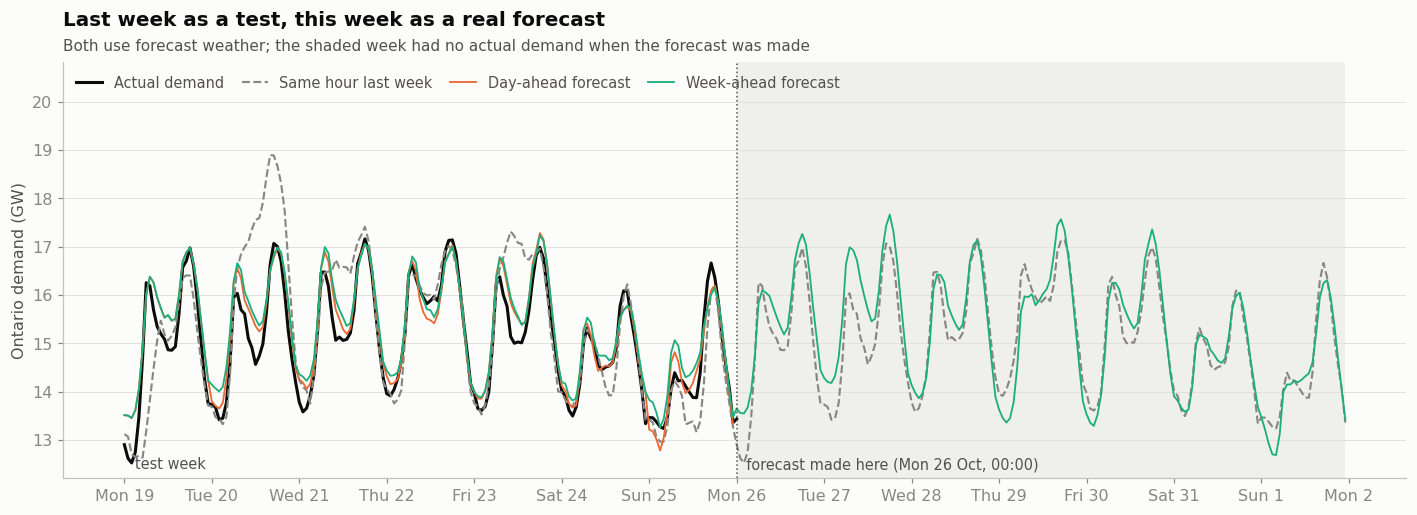

In [3]:
def fetch_live():
    return pd.read_parquet(METAGRID / "results" / "live" / "week_2026-10-26.parquet")


live = load_data("live_week", fetch_live).set_index("datetime")
live_origin = live.index[live.week == "forecast"][0]
xs = live.index
fig, ax = plt.subplots(figsize=(13, 4.8))
ax.axvspan(live_origin, xs[-1], color=C["grid"], alpha=0.45, lw=0)
ax.plot(xs, live.actual / 1000, color=C["ink"], lw=2.0, label="Actual demand")
lt = live[live.week == "test"]
ax.plot(xs, live.naive_week / 1000, color=C["muted"], lw=1.4, ls="--", label="Same hour last week")
ax.plot(lt.index, lt.day_ahead_nwp / 1000, color=C["orange"], lw=1.2, label="Day-ahead forecast")
ax.plot(xs, live.week_ahead_nwp / 1000, color=C["aqua"], lw=1.2, label="Week-ahead forecast")
ax.axvline(live_origin, color=C["ink2"], lw=1, ls=":")
ax.text(live_origin, 0.015, "  forecast made here (Mon 26 Oct, 00:00)", transform=ax.get_xaxis_transform(),
        color=C["ink2"], fontsize=9.5, va="bottom")
ax.text(lt.index[3], 0.015, "test week", transform=ax.get_xaxis_transform(), color=C["ink2"], fontsize=9.5, va="bottom")
ax.set_ylabel("Ontario demand (GW)")
ax.set_ylim(top=ax.get_ylim()[1] + 1.6)
ax.legend(loc="upper left", ncols=4, fontsize=9.5, columnspacing=1.2, handlelength=1.8)
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %-d"))
headline(ax, "Last week as a test, this week as a real forecast",
         "Both use forecast weather; the shaded week had no actual demand when the forecast was made")
plt.tight_layout(); plt.show()

In [4]:
lw = live[live.week == "test"]
rows = {"Same hour last week": "naive_week", "Same hour yesterday": "naive_day",
        "Day-ahead forecast, observed weather (the backtests' setting)": "day_ahead_obs", "Day-ahead forecast, forecast weather": "day_ahead_nwp",
        "Week-ahead forecast, observed weather": "week_ahead_obs", "Week-ahead forecast, forecast weather": "week_ahead_nwp"}
mae_t = pd.DataFrame({"MAE (MW)": {k: (lw[c] - lw.actual).abs().mean() for k, c in rows.items()}})
mae_t["MAPE (%)"] = {k: ((lw[c] - lw.actual).abs() / lw.actual).mean() * 100 for k, c in rows.items()}
mae_t.index.name = "test week, 19 to 25 October"
show_md(mae_t.round({"MAE (MW)": 0, "MAPE (%)": 2}), code_index=False)

| test week, 19 to 25 October | MAE (MW) | MAPE (%) |
|---|---:|---:|
| Same hour last week | 566 | 3.71 |
| Same hour yesterday | 513 | 3.43 |
| Day-ahead forecast, observed weather (the backtests' setting) | 249 | 1.68 |
| Day-ahead forecast, forecast weather | 290 | 1.96 |
| Week-ahead forecast, observed weather | 282 | 1.91 |
| Week-ahead forecast, forecast weather | 347 | 2.36 |

In the test week the day-ahead forecast, with forecast weather, misses by about **290 MW** (a MAPE of 2.0%), against 513 MW for repeating yesterday and 566 MW for repeating last week: **43% less error than "same hour
yesterday"**, close to the 49% of the 2025 test year. Forecast weather cost about 40 MW compared with the observed
weather the backtests use (249 MW), which is a first idea of how far those backtests sit from a deployed model.
Taking away the daily update costs a little more: **347 MW** for the week-ahead forecast, still 39% below
"same hour last week". Day by day the week-ahead forecast's error does not rise steadily with the horizon (by day it was 460, 495, 373, 173,
342, 248 and 341 MW from Monday to Sunday): Monday and Tuesday were the hardest days for every variant, Thursday the
easiest. One week is a small sample, but it suggests the daily update is worth tens of MW, not hundreds.

The forecast week, in the shaded part of the figure: weekdays average 15.4 to 15.9 GW with the peak on Tuesday evening
at about 17.7 GW, falling to 14.7 GW on Saturday and 14.3 GW on Sunday, 1 November. I did not tune anything on the test
week, and the forecast cannot be judged until the demand arrives; the same pipeline run a week from now will say how it did.

## Key takeaways

- **A day-ahead error of 390 MW (2.3%), 49% below "same hour yesterday".** On the 2025 test year the model's mean absolute
  error (MAE) was 389.5 MW, a mean absolute percentage error (MAPE) of 2.33%, against 758 MW (4.58%) for repeating
  yesterday. On January to September 2026, data that arrived after every choice had been made, the saving is the same:
  417 MW (2.46%) against 838 MW (4.95%), 50%.
- **The two halves need each other.** SARIMA on the demand history alone reaches 617 MW; with a weather-and-calendar
  regression underneath, the very first version reached 467 MW.
- **A yearly cycle, a trend and a longer training window were worth about 26 MW** in the cross-validation, because demand
  has a seasonal shape that temperature does not explain and it drifts upward.
- **They also removed the need to difference.** With them the residuals pass the stationarity tests, and in the
  cross-validation every model without a plain difference beat every model with one, the best by 7.0 ± 1.4 MW.
- **Estimating the SARIMA part on 90 days is as good as on two years:** within 1 MW, in a quarter of the time.
- **Where it fails:** holidays and the days next to them, and the middle of the day. And these numbers use the
  *observed* weather, so they are an upper bound for a model that has to use weather forecasts: in the
  live check at the top, forecast weather cost about 17% more error.

## The task, and how to keep it honest

**What is being forecast.** Every day at midnight, the model has to predict the next 24 hours of Ontario demand using only
what was known up to that moment: the *day-ahead* task. The error is measured by the **mean absolute error (MAE)** in MW and its percentage version, the **mean absolute percentage error (MAPE)**, both averaged over every forecast hour; models are chosen on the MAE, and the two tell the same story. The yardstick is the simplest
thing that works, *the same hour yesterday*.

**How to evaluate without fooling yourself.**

- **Walk forward.** Parameters are re-estimated on the first of each month from data before that month, then frozen.
  Inside the month the model only watches the actual demand arrive, day by day. Nothing from the future leaks in.
- **Choose on validation years, test once.** Orders, windows and extra terms were chosen with a rolling-origin
  cross-validation on 2022 to 2024: every month is one fold, 36 in all. 2025 is the test year, looked at once at the end.
- **A holdout that arrived later.** January to September 2026 was added after all the choices were frozen.
- **Weather is observed, not forecast.** The model is given the temperature that actually happened on the forecast day. (The live check
  at the top is the exception: it uses forecast weather.)

The long backtests (several hundred model fits) are saved locally.

In [5]:
def run(name, period="test 2025"):
    f = backtests[(backtests.run == name) & (backtests.period == period)]
    return f.set_index("target_time")


mae = lambda f: (f.forecast - f.actual).abs().mean()   # MAE of a frame with forecast and actual


## Step 1: a regression on weather and the calendar

Start with what demand *should* be, given the weather and the calendar. Ordinary least squares writes demand as a
sum of terms, and everything I found in the previous post becomes a column:

- **Temperature as two hinges.** Demand rises on both sides of a comfortable range, so heating degrees are
  `max(11 − T, 0)` and cooling degrees `max(T − 16, 0)`, each with its own slope.
- **Humidity makes heat cost more:** cooling degrees times the dew point.
- **The shape of the day:** waves with periods of 24 and 12 hours.
- **Day types that change that shape:** Saturday, Sunday, holidays and Christmas week.

In [6]:
HARMONICS = ["sin24", "cos24", "sin12", "cos12"]


def design_matrix(df, annual_cycle=0, trend=False):
    """The regressors: weather, calendar, and optionally a yearly cycle and a trend."""
    X = pd.DataFrame(index=df.index)
    # Weather: the U-curve of demand against temperature as two hinges, and humidity making heat cost more.
    X["heat_deg"] = np.maximum(11.0 - df["temp_c"], 0)
    X["cool_deg"] = np.maximum(df["temp_c"] - 16.0, 0)
    X["cool_x_dew"] = X["cool_deg"] * df["dew_c"]
    # Calendar: the shape of the day (24 h and 12 h waves), and day types that change that shape.
    hour = df.index.hour.to_numpy()
    waves = {"sin24": np.sin(2 * np.pi * hour / 24), "cos24": np.cos(2 * np.pi * hour / 24),
             "sin12": np.sin(4 * np.pi * hour / 24), "cos12": np.cos(4 * np.pi * hour / 24)}
    X["is_xmas_week"] = df["is_xmas_week"]
    for name, wave in waves.items():
        X[name] = wave
    for day, flag in [("is_saturday", df.index.dayofweek == 5), ("is_sunday", df.index.dayofweek == 6),
                      ("is_holiday", df["is_holiday"])]:
        X[day] = flag
        for name, wave in waves.items():
            X[f"{day}_x_{name}"] = flag * wave          # a day type is not a flat shift: it changes the daily shape
    doy = df.index.dayofyear.to_numpy()
    for k in range(1, annual_cycle + 1):                 # yearly cycle: K sine/cosine pairs of the day of the year
        X[f"ann_sin{k}"] = np.sin(2 * np.pi * k * doy / 365.2425)
        X[f"ann_cos{k}"] = np.cos(2 * np.pi * k * doy / 365.2425)
    if trend:
        X["trend_years"] = (df.index.year - 2017) + (doy - 1) / 365.25
    return X.astype(float)


# Hourly series on a gap-free index (the odd missing hour is interpolated), as the backtests use it.
hourly = hourly.asfreq("h").astype(float).interpolate(limit=3)
y = hourly["demand_mw"]
base = design_matrix(hourly)
base.shape

(61368, 23)

That is 23 columns. One choice deserves a word: a day type is not a flat shift. A Sunday is lighter because offices, shops
and factories are closed, which is a *daytime* effect, so each day type gets its own copy of the daily waves. A flat
"Sunday" dummy would lower demand by the same amount at 3 a.m. as at 3 p.m.

In [7]:
# The window of the first steps: the two years before the 2024 validation year.
window = slice("2022-01-01", "2023-12-31 23:00")
plain = sm.OLS(y.loc[window], sm.add_constant(base.loc[window])).fit()
# The residuals are strongly autocorrelated (next step), so the usual standard errors are far too small.
# HAC (Newey-West) errors allow for autocorrelation up to 48 hours.
plain_hac = sm.OLS(y.loc[window], sm.add_constant(base.loc[window])).fit(cov_type="HAC", cov_kwds={"maxlags": 48})


def block_tests(model, blocks):
    """One joint test per block of related terms: a day type and its interactions belong together."""
    tests = {name: model.wald_test(", ".join(f"{m} = 0" for m in cols), scalar=True) for name, cols in blocks.items()}
    return pd.DataFrame({"chi2": {k: float(v.statistic) for k, v in tests.items()},
                         "p-value": {k: float(v.pvalue) for k, v in tests.items()}})


blocks = {
    "weather": ["heat_deg", "cool_deg", "cool_x_dew"],
    "daily profile": HARMONICS,
    "Saturday": ["is_saturday"] + [f"is_saturday_x_{h}" for h in HARMONICS],
    "Sunday": ["is_sunday"] + [f"is_sunday_x_{h}" for h in HARMONICS],
    "holiday": ["is_holiday"] + [f"is_holiday_x_{h}" for h in HARMONICS],
}
print(f"R2 {plain.rsquared:.3f}, residual sd {plain.resid.std():,.0f} MW")
block_tests(plain_hac, blocks).round(4)

R2 0.886, residual sd 754 MW


,chi2,p-value
weather,4592.6327,0.0
daily profile,23341.2258,0.0
Saturday,1110.1505,0.0
Sunday,1630.0109,0.0
holiday,177.8458,0.0


The regression is fitted on a fixed two-year window, 1 January 2022 to 31 December 2023 (730 days, 17,520 hours), and explains **89% of the variance** (R² = 0.886). Every block of
terms is overwhelmingly significant: the weather (joint χ² = 4,593), the daily profile (23,341), Saturday (1,110), Sunday
(1,630) and holidays (178). Holidays are the weakest block, which makes sense: a year has only about ten of them, so
their hour-by-hour shape is estimated from very few days.

One detail matters more than it looks. The standard errors are the robust (HAC) ones. As the next step shows, the errors
of this regression are strongly autocorrelated, and the usual standard errors, which assume independent errors, would make
every term look several times more significant than it is.

In [8]:
# Every coefficient, with the robust (HAC) standard error that the tests above use.
# The plain OLS standard error is shown next to it to see how much too small it would be.
stars = lambda p: r"\*\*\*" if p < 0.001 else r"\*\*" if p < 0.01 else r"\*" if p < 0.05 else ""
coef_table = pd.DataFrame({
    "coefficient (MW)": plain_hac.params, "HAC se": plain_hac.bse, "t": plain_hac.tvalues,
    "p-value": [f"{p:.4f}" if p >= 0.0001 else "<0.0001" for p in plain_hac.pvalues], "": [stars(p) for p in plain_hac.pvalues], "plain OLS se": plain.bse,
})
show_md(coef_table.round({"coefficient (MW)": 1, "HAC se": 1, "t": 1, "plain OLS se": 1}))


|  | coefficient (MW) | HAC se | t | p-value |  | plain OLS se |
|---|---:|---:|---:|---:|---:|---:|
| `const` | 14,410 | 44.4 | 324.4 | <0.0001 | \*\*\* | 10.1 |
| `heat_deg` | 177.9 | 3.1 | 57.2 | <0.0001 | \*\*\* | 0.9 |
| `cool_deg` | -60.6 | 27.6 | -2.2 | 0.0283 | \* | 7 |
| `cool_x_dew` | 30.9 | 1.6 | 19 | <0.0001 | \*\*\* | 0.4 |
| `is_xmas_week` | 85.4 | 132.9 | 0.6 | 0.5205 |  | 38.6 |
| `sin24` | -1,144.5 | 21.1 | -54.3 | <0.0001 | \*\*\* | 9.9 |
| `cos24` | -1,259 | 24.4 | -51.6 | <0.0001 | \*\*\* | 10 |
| `sin12` | -668.2 | 9.4 | -71.1 | <0.0001 | \*\*\* | 9.7 |
| `cos12` | -769.6 | 12.1 | -63.5 | <0.0001 | \*\*\* | 9.7 |
| `is_saturday` | -1,027.4 | 55.5 | -18.5 | <0.0001 | \*\*\* | 16.5 |
| `is_saturday_x_sin24` | 21.3 | 43.6 | 0.5 | 0.6249 |  | 23.3 |
| `is_saturday_x_cos24` | 422 | 46.1 | 9.1 | <0.0001 | \*\*\* | 23.3 |
| `is_saturday_x_sin12` | 230.3 | 23.1 | 10 | <0.0001 | \*\*\* | 23.3 |
| `is_saturday_x_cos12` | 341.8 | 23 | 14.9 | <0.0001 | \*\*\* | 23.3 |
| `is_sunday` | -1,217.5 | 56.3 | -21.6 | <0.0001 | \*\*\* | 16.5 |
| `is_sunday_x_sin24` | -371.9 | 40.2 | -9.2 | <0.0001 | \*\*\* | 23.3 |
| `is_sunday_x_cos24` | 542 | 45.4 | 11.9 | <0.0001 | \*\*\* | 23.3 |
| `is_sunday_x_sin12` | 220 | 23.9 | 9.2 | <0.0001 | \*\*\* | 23.3 |
| `is_sunday_x_cos12` | 278.6 | 23.7 | 11.8 | <0.0001 | \*\*\* | 23.3 |
| `is_holiday` | -1,367 | 136 | -10.1 | <0.0001 | \*\*\* | 34.9 |
| `is_holiday_x_sin24` | -182.2 | 80.5 | -2.3 | 0.0237 | \* | 47.2 |
| `is_holiday_x_cos24` | 400.7 | 110 | 3.6 | 0.0003 | \*\*\* | 47.2 |
| `is_holiday_x_sin12` | 229.3 | 50.7 | 4.5 | <0.0001 | \*\*\* | 47.2 |
| `is_holiday_x_cos12` | 320.4 | 48.1 | 6.7 | <0.0001 | \*\*\* | 47.2 |

All 24 coefficients, in MW per unit of the column (`***` p < 0.001, `**` p < 0.01, `*` p < 0.05). Two terms are not
significant: Christmas week (p = 0.52, nine days a year, and the holiday terms already cover most of it) and the
Saturday × sin24 wave (p = 0.62). Everything else is, but read the weather rows together. The cooling-degree slope on its
own is *negative* (−61 MW per degree) and barely significant, because it is only the slope at a dew point of zero; with the
humidity term the slope is −61 + 31 × dew point, which is positive once the dew point passes about 2 °C, and in summer it
always does. The last column shows what the correction is worth: for the cooling slope the plain standard error is 7.0
against a robust 27.6, so ignoring the autocorrelation would have called it a 8.6-sigma effect instead of 2.2.

**What's the training window?** This step uses one fixed window, the two years before the 2024 validation year, and it exists to explain
and test the regression, not to forecast. The backtests behind the later steps work differently: on the first of every
month the regression is refitted on the *previous 730 days* (the same length as here, but rolling forward), the SARIMA
part is estimated on the last 90 days only (steps 7 and 8), and everything is then frozen for the month. So the coefficients of
a given backtest month differ slightly from this table.


## Step 2: what the regression leaves behind

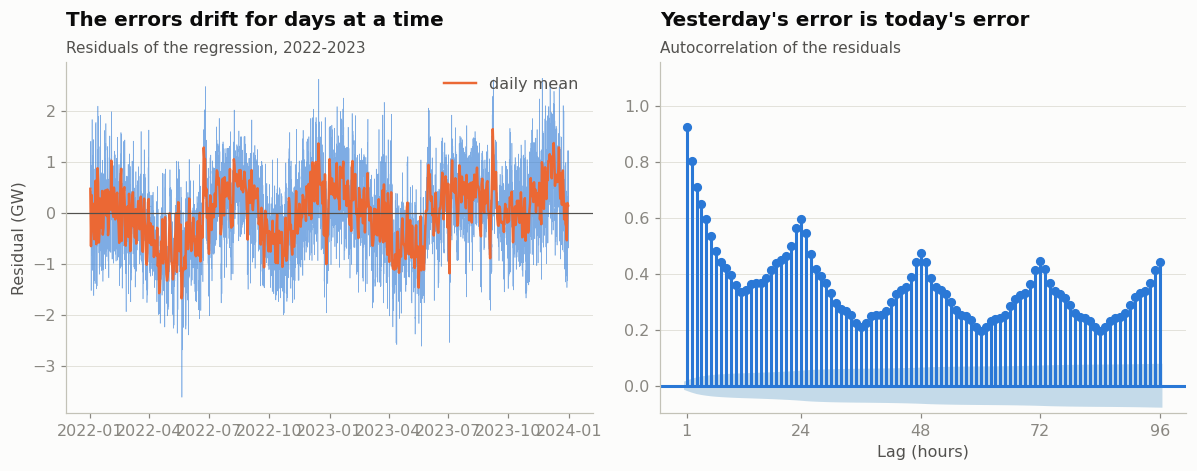

residual sd 754 MW; autocorrelation at 1 h 0.92, 24 h 0.59, 168 h 0.44; Durbin-Watson 0.15


In [9]:
resid_plain = plain.resid
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
ax.plot(resid_plain.index, resid_plain / 1000, color=C["blue"], lw=0.4, alpha=0.6)
ax.plot(resid_plain.resample("D").mean().index, resid_plain.resample("D").mean() / 1000, color=C["orange"], lw=1.6, label="daily mean")
ax.axhline(0, color=C["ink2"], lw=0.8)
ax.set_ylabel("Residual (GW)"); ax.legend(loc="upper right")
headline(ax, "The errors drift for days at a time", "Residuals of the regression, 2022-2023")
ax = axes[1]
plot_acf(resid_plain, lags=96, zero=False, title="", ax=ax, color=C["blue"], vlines_kwargs={"colors": C["blue"]}, auto_ylims=True)
ax.set_xticks([1, 24, 48, 72, 96]); ax.set_xlabel("Lag (hours)")
headline(ax, "Yesterday's error is today's error", "Autocorrelation of the residuals")
plt.tight_layout(); plt.show()
r = acf(resid_plain, nlags=168)
print(f"residual sd {resid_plain.std():,.0f} MW; autocorrelation at 1 h {r[1]:.2f}, 24 h {r[24]:.2f}, 168 h {r[168]:.2f}; "
      f"Durbin-Watson {sm.stats.durbin_watson(resid_plain):.2f}")

An R² near 0.9 can hide a lot. The residuals are not noise: they **drift for days at a time**, and their autocorrelation is
0.92 at one hour, 0.59 at 24 hours and still 0.44 at a week. The Durbin-Watson statistic is 0.15, where 2 would mean no
autocorrelation at all.

What a regression on weather and calendar cannot know is *momentum*. If demand ran 1 GW above the prediction in this hour,
it probably will in the next hour, and tomorrow at the same time. Modelling that is the job of the SARIMA part, and
it is why the regression on its own makes a poor forecaster.

## Step 3: a yearly cycle and a trend

I could see two things missing in those residuals, and both are about the slow part of demand:

- **A trend.** Ontario's demand has been growing again after a decade of decline, so a regression fitted on the past
  keeps under-forecasting the present.
- **A yearly cycle** that temperature does not explain (daylight, the school year, summer vacations). I model it with
  two sine and cosine pairs of the day of the year, enough for a shape with two peaks per year.

In [10]:
# The same regression with a yearly cycle (two sine/cosine pairs) and a linear trend added.
extended = sm.add_constant(design_matrix(hourly, annual_cycle=2, trend=True).loc[window])
fit = sm.OLS(y.loc[window], extended).fit()
fit_hac = sm.OLS(y.loc[window], extended).fit(cov_type="HAC", cov_kwds={"maxlags": 48})
resid = fit.resid

new_blocks = {"yearly cycle": ["ann_sin1", "ann_cos1", "ann_sin2", "ann_cos2"], "trend": ["trend_years"]}
print(f"R2 {plain.rsquared:.3f} -> {fit.rsquared:.3f}; residual sd {plain.resid.std():,.0f} -> {resid.std():,.0f} MW; "
      f"trend {fit.params['trend_years']:+,.0f} MW per year")
block_tests(fit_hac, new_blocks).round(4)

R2 0.886 -> 0.922; residual sd 754 -> 624 MW; trend +204 MW per year


,chi2,p-value
yearly cycle,584.1226,0.0
trend,30.2769,0.0


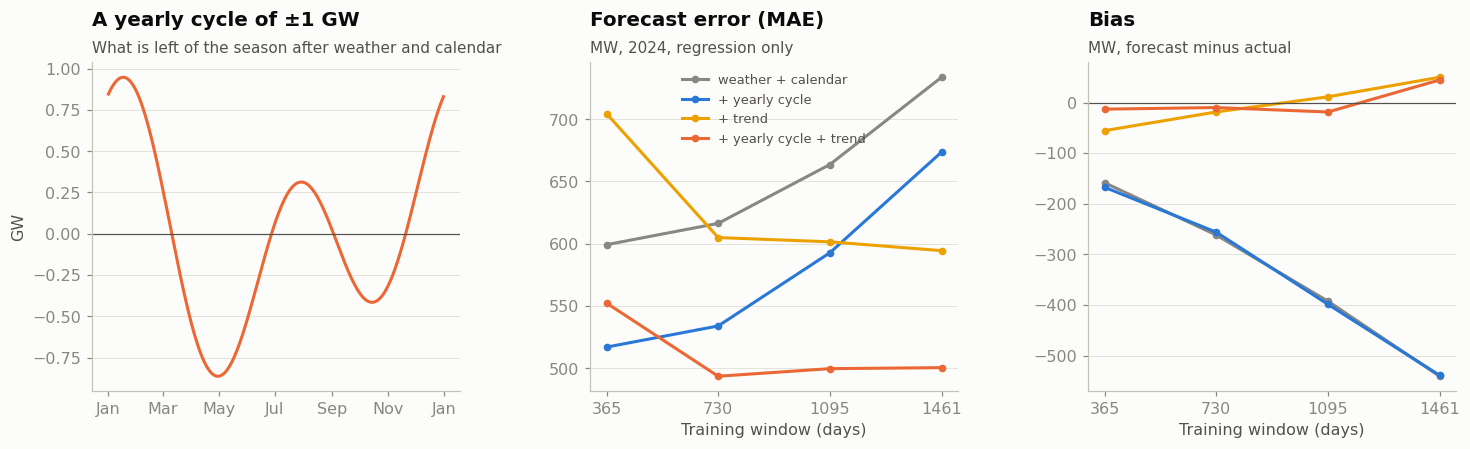

autocorrelation of the residuals at 24 h 0.59 -> 0.50, at 168 h 0.44 -> 0.28; Durbin-Watson 0.15 -> 0.21


In [11]:
days = pd.date_range("2023-01-01", "2023-12-31")
doy = days.dayofyear.to_numpy()
f_cycle = sum(fit.params[f"ann_sin{k}"] * np.sin(2 * np.pi * k * doy / 365.2425)
              + fit.params[f"ann_cos{k}"] * np.cos(2 * np.pi * k * doy / 365.2425) for k in (1, 2))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2))
ax = axes[0]
ax.plot(days, (f_cycle - f_cycle.mean()) / 1000, color=C["orange"])
ax.axhline(0, color=C["ink2"], lw=0.8)
ax.set_ylabel("GW")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
headline(ax, "A yearly cycle of ±1 GW", "What is left of the season after weather and calendar")
grid = ols_grid.assign(variant=lambda d: np.select([d.annual & d.trend, d.annual, d.trend], ["+ yearly cycle + trend", "+ yearly cycle", "+ trend"], "weather + calendar"))
palette = {"weather + calendar": C["muted"], "+ yearly cycle": C["blue"], "+ trend": C["yellow"], "+ yearly cycle + trend": C["orange"]}
for ax, col, title, sub in [(axes[1], "mae", "Forecast error (MAE)", "MW, 2024, regression only"), (axes[2], "bias", "Bias", "MW, forecast minus actual")]:
    for v, color in palette.items():
        g = grid[grid.variant == v].sort_values("train_days")
        if len(g):
            ax.plot(g.train_days.astype(str), g[col], marker="o", ms=4, color=color, label=v)
    ax.set_xlabel("Training window (days)")
    headline(ax, title, sub)
axes[2].axhline(0, color=C["ink2"], lw=0.8)
axes[1].legend(fontsize=8.5)
plt.tight_layout(); plt.show()

print(f"autocorrelation of the residuals at 24 h {acf(plain.resid, nlags=24)[24]:.2f} -> {acf(resid, nlags=24)[24]:.2f}, "
      f"at 168 h {acf(plain.resid, nlags=168)[168]:.2f} -> {acf(resid, nlags=168)[168]:.2f}; Durbin-Watson {sm.stats.durbin_watson(plain.resid):.2f} -> {sm.stats.durbin_watson(resid):.2f}")

The fitted cycle (left) is double-peaked: about +0.9 GW in January, −0.9 GW in May, a second bump in August. Together with
a trend of **+204 MW per year** it lifts the in-sample R² from 0.886 to 0.922 and shrinks the residual standard deviation
from 754 to 624 MW; the autocorrelation at 24 hours falls from 0.59 to 0.50 and at a week from 0.44 to 0.28. Both blocks
are significant (χ² = 584 and 30).

The other two panels show what this is worth **out of sample**: the plain regression alone, fitted monthly and used to
forecast 2024. Without the extra terms a longer training window makes things *worse* (MAE 599 MW with 365 days, 734 MW
with 1,461 days; the bias goes from −158 to −541 MW), because the regression learns an old level while demand keeps rising.
The yearly cycle alone helps at 365 days (517 MW) but has the same problem with longer windows. With the trend as well, a
longer window helps instead: 494 MW with 730 days, with a bias of only −10 MW. A trend inside a single year cannot be told
apart from the season, so the two come together with a **730-day window**.

## Step 4: stationary or not? How much to difference?

SARIMA models want a stationary series: a stable mean and spread. If the series drifts, the usual cure is to
**difference** it, which means subtracting the previous value (`d`) or the value one season ago (`D`, here 24 hours).
Differencing is not free: it throws away information and, done unnecessarily, adds noise.

Two tests look at this from opposite sides. **ADF** has "there is a unit root" as its null; **KPSS** has "the series is
stationary" as its null. If they agree you know; if they disagree the series is stationary around something that moves.

In [12]:
def unit_root(series, name):
    """ADF (null: a unit root) and KPSS (null: stationary) side by side."""
    s = series.dropna()
    adf, kp = adfuller(s, autolag="AIC"), kpss(s, regression="c", nlags="auto")
    return {"series": name, "ADF p": adf[1], "KPSS stat": kp[0], "KPSS p": kp[1],
            "verdict": "stationary" if adf[1] < 0.05 and kp[1] >= 0.05 else
                       "unit root" if kp[1] < 0.05 and adf[1] >= 0.05 else "the tests disagree"}

pd.DataFrame([
    unit_root(plain.resid, "residual, plain regression"),
    unit_root(resid, "residual, with yearly cycle and trend"),
    unit_root(resid.diff(24), "   ... after a seasonal difference (24 h)"),
    unit_root(resid.diff().diff(24), "   ... after a difference and a seasonal difference"),
]).set_index("series").round(3)

,ADF p,KPSS stat,KPSS p,verdict
series,,,,
"residual, plain regression",0.0,2.348,0.01,the tests disagree
"residual, with yearly cycle and trend",0.0,0.170,0.10,stationary
... after a seasonal difference (24 h),0.0,0.005,0.10,stationary
... after a difference and a seasonal difference,0.0,0.016,0.10,stationary


For the plain regression the two tests **disagree**: ADF rejects the unit root, KPSS rejects stationarity (a statistic of
2.35 against a 5% critical value of 0.463). That is the signature of a level that drifts, and it is exactly what the trend
and the yearly cycle were for. With them, ADF still rejects the unit root and KPSS no longer rejects stationarity (0.17), so
**the plain difference is not needed: d = 0**.

A seasonal difference is another matter. The autocorrelation at 24 hours is still 0.50, so I keep one (`D = 1`: subtract the
same hour of the previous day) and look at what is left.

## Step 5: reading the ACF and the PACF

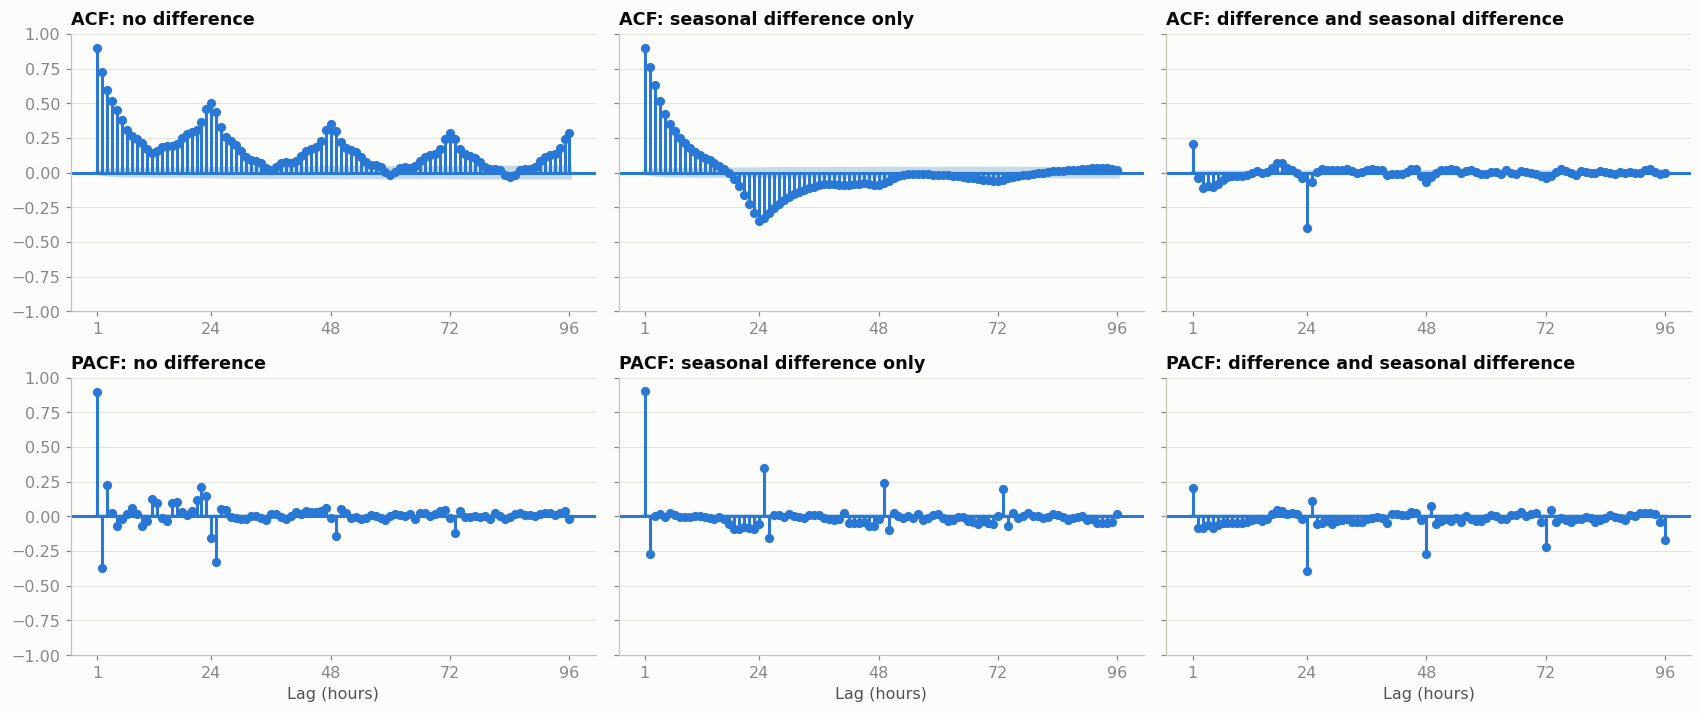

no difference
        1     2     3     6     12    24    25    48    72
ACF   0.89  0.73  0.60  0.38  0.14  0.50  0.44  0.35  0.29
PACF  0.89 -0.37  0.23 -0.02  0.12 -0.16 -0.33 -0.01 -0.01
seasonal difference only
       1     2     3     6     12    24    25    48    72
ACF   0.9  0.76  0.63  0.35  0.13 -0.35 -0.33 -0.09 -0.06
PACF  0.9 -0.27  0.01  0.03  0.01 -0.06  0.35 -0.02  0.01


In [13]:
s_seas = resid.diff(24).dropna()                 # seasonal difference only (D = 1)
s_both = resid.diff().diff(24).dropna()          # plus a plain difference (d = 1, D = 1)
fig, axes = plt.subplots(2, 3, figsize=(15.5, 6.6), sharey="row")
for col, (s, label) in enumerate([(resid.dropna(), "no difference"), (s_seas, "seasonal difference only"),
                                  (s_both, "difference and seasonal difference")]):
    for row, plot in enumerate([plot_acf, plot_pacf]):
        ax = axes[row, col]
        plot(s, lags=96, zero=False, title="", ax=ax, color=C["blue"], vlines_kwargs={"colors": C["blue"]},
             **({"method": "ywm"} if plot is plot_pacf else {}))
        ax.set_xticks([1, 24, 48, 72, 96])
        ax.set_title(f"{'ACF' if row == 0 else 'PACF'}: {label}", loc="left", fontsize=11.5, fontweight="bold")
        ax.set_xlabel("Lag (hours)" if row else "")
plt.tight_layout(); plt.show()
lags = [1, 2, 3, 6, 12, 24, 25, 48, 72]
for name, ser in [("no difference", resid.dropna()), ("seasonal difference only", s_seas)]:
    print(name)
    print(pd.DataFrame({"ACF": acf(ser, nlags=96)[lags], "PACF": pacf(ser, nlags=96, method="ywm")[lags]}, index=lags).round(2).T.to_string())

Reading these plots is a craft with two rules of thumb: an **AR** term shows as a PACF that cuts off and an ACF that fades;
an **MA** term is the other way around.

- **The left column, no difference at all:** the daily part already has the look of the middle column (an ACF fading from 0.89, a PACF with its big bars at lags 1 to 3), but at the seasonal lags the ACF stays high and fades slowly: 0.50 at 24 hours, 0.35 at 48 and 0.29 at 72. That is the reason for the seasonal difference (`D = 1`); the middle column shows what is left after it.
- **The non-seasonal part, middle column:** the PACF is large at lags 1 and 2 (0.90 and −0.27) and within ±0.03 up to lag 12,
  while the ACF fades geometrically (0.90, 0.76, 0.63, then 0.35 at 6 hours and 0.13 at 12). That is an **AR(2)**.
- **The seasonal part:** the ACF is −0.35 at lag 24, but only −0.09 and −0.06 at lags 48 and 72, so it cuts off after one
  seasonal lag, while the PACF has a spike beside each seasonal lag (0.35 at 25) that fades slowly. That is a
  **seasonal MA(1)**.
- **The right column** shows what an extra plain difference does: a positive spike at lag 1 and a slowly fading negative
  tail, the mark of over-differencing, which a model could only undo with an MA coefficient of −1.

So the starting point is SARIMA(2,0,0)(0,1,1) with a 24-hour season. With 17,520 hours the 95% band is only ±0.015, so
nearly every bar is "significant": what counts is the size and the pattern.

## Step 6: choosing the order

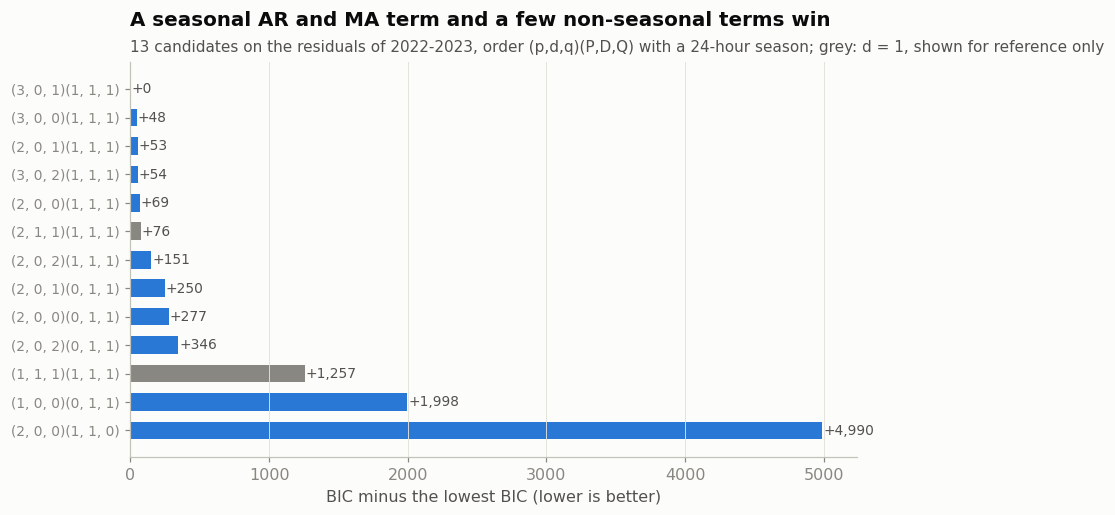

             label      aic      bic       llf
(3, 0, 1)(1, 1, 1) 235984.3 236038.7 -117985.1
(3, 0, 0)(1, 1, 1) 236040.5 236087.2 -118014.3
(2, 0, 1)(1, 1, 1) 236045.5 236092.1 -118016.7
(3, 0, 2)(1, 1, 1) 236031.0 236093.2 -118007.5
(2, 0, 0)(1, 1, 1) 236068.7 236107.6 -118029.4
(2, 0, 2)(1, 1, 1) 236134.9 236189.3 -118060.4
(2, 0, 1)(0, 1, 1) 236250.0 236288.8 -118120.0
(2, 0, 0)(0, 1, 1) 236285.0 236316.1 -118138.5
(2, 0, 2)(0, 1, 1) 236337.9 236384.5 -118162.9
(1, 0, 0)(0, 1, 1) 238013.0 238036.3 -119003.5
(2, 0, 0)(1, 1, 0) 240997.8 241028.8 -120494.9


In [14]:
o = orders.assign(label=lambda d: d.order + d.seasonal).sort_values("bic")
o["dbic"] = o.bic - o.bic.min()
fig, ax = plt.subplots(figsize=(9.5, 4.8))
colors = [C["orange"] if i == 0 else C["blue"] if d == 0 else C["muted"] for i, d in enumerate(o.d)]
ax.barh(o.label[::-1], o.dbic[::-1], color=colors[::-1], height=0.62)
for i, (v, l) in enumerate(zip(o.dbic[::-1], o.label[::-1])):
    ax.text(v + 6, i, f"+{v:,.0f}", va="center", fontsize=9, color=C["ink2"])
ax.set_xlabel("BIC minus the lowest BIC (lower is better)")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=9)
headline(ax, "A seasonal AR and MA term and a few non-seasonal terms win", "13 candidates on the residuals of 2022-2023, order (p,d,q)(P,D,Q) with a 24-hour season; grey: d = 1, shown for reference only")
plt.tight_layout(); plt.show()
same_d = o[(o.d == 0) & (o.D == 1)]
print(same_d[["label", "aic", "bic", "llf"]].round(1).to_string(index=False))

With a starting point, let the data compare neighbours by AIC and BIC (fit quality minus a price per parameter). They are
only comparable between models that difference the same way, so the grey `d = 1` bars are just for reference.

- **The seasonal MA is indispensable** (dropping it costs +4,990 BIC), and so is the second AR term
  (+1,998 with a single AR term, +277 with two).
- **A seasonal AR term pays for itself:** (2,0,1) goes from +250 to +53 when it is added.
- **Beyond that the gains are small:** the best, (3,0,1)(1,1,1), is only 48 to 69 BIC points ahead of its neighbours.

One row is a warning: (2,0,2)(1,1,1) comes out *worse* than (2,0,1)(1,1,1), the model it contains (log-likelihood
−118,060 against −118,017). A maximum-likelihood fit cannot do that, so the optimiser stopped at a local optimum. The
information criteria give a shortlist, not a verdict, and the decision is made by forecasting error.

## Step 7: one backtest month, by hand

Before the cross-validation, here is exactly what one month of a backtest does. On the first of the month:

1. fit the **regression** on the previous 730 days;
2. estimate the **SARIMA parameters** on the residuals of the last 90 days only;
3. filter the last 30 days of residuals through the fitted model to set its state.

Then, for every day of the month: forecast the next 24 hours at midnight (the SARIMA forecast of the residual plus the
regression), and once the day is over, show the model its actual values and move on. The parameters stay fixed inside the
month.

In [15]:
def backtest_month(first_day, order=(2, 0, 2), seasonal=(1, 1, 1, 24), train_days=730, sarima_days=90, state_days=30):
    """Forecast every day of one month, the way the backtests do: refit once, then roll the filter forward daily."""
    first = pd.Timestamp(first_day)
    last_hour = first - pd.Timedelta(hours=1)

    # Step 1: the regression, estimated on the previous 730 days.
    X = sm.add_constant(design_matrix(hourly, annual_cycle=2, trend=True))
    train = slice(first - pd.Timedelta(days=train_days), last_hour)
    beta = sm.OLS(y.loc[train], X.loc[train]).fit().params
    regression = X @ beta
    resid = y - regression

    # Step 2: the SARIMA parameters, estimated on the residuals of the last 90 days only.
    sarima = SARIMAX(resid.loc[first - pd.Timedelta(days=sarima_days):last_hour], order=order, seasonal_order=seasonal)
    params = sarima.fit(disp=False, maxiter=200, low_memory=True).params

    # Step 3: filter the last 30 days with those parameters, then forecast a day, learn its actuals, and move on.
    state = SARIMAX(resid.loc[first - pd.Timedelta(days=state_days):last_hour], order=order, seasonal_order=seasonal).filter(params)
    out = []
    for day in pd.date_range(first, first + pd.offsets.MonthEnd(0)):
        hours = pd.date_range(day, periods=24, freq="h")
        forecast = state.forecast(24).to_numpy() + regression.loc[hours].to_numpy()   # what we know at 00:00
        out.append(pd.DataFrame({"forecast": forecast, "actual": y.loc[hours].to_numpy()}, index=hours))
        state = state.extend(resid.loc[hours])                                         # 24 hours later we know the day
    return pd.concat(out), params


july, july_params = backtest_month("2025-07-01")
july_params.round(3)

ar.L1           1.090
ar.L2          -0.206
ma.L1           0.064
ma.L2           0.043
ar.S.L24        0.112
ma.S.L24       -0.933
sigma2      45953.967
dtype: float64

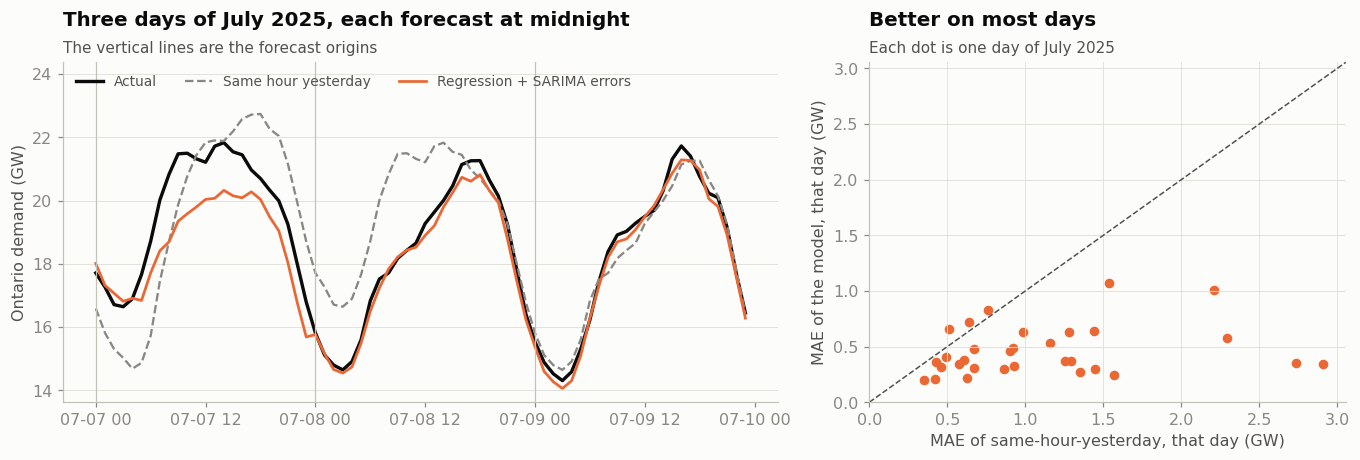

July 2025 MAE: model 463 MW, same hour yesterday 1,107 MW; better on 90% of the days
this hand-made run vs the saved backtest: largest difference 0.16 MW, mean 0.049 MW


In [16]:
saved = run("sarimax_final").loc["2025-07-01":"2025-07-31 23:00"]
naive = run("naive_day").loc["2025-07-01":"2025-07-31 23:00"]
diff = (july.forecast - saved.forecast).abs()
daily = pd.DataFrame({"model": (july.forecast - july.actual).abs().groupby(july.index.normalize()).mean(),
                      "naive": (naive.forecast - naive.actual).abs().groupby(naive.index.normalize()).mean()})

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
two = slice("2025-07-07", "2025-07-09 23:00")
ax.plot(july.loc[two].index, july.loc[two].actual / 1000, color=C["ink"], lw=2.2, label="Actual")
ax.plot(naive.loc[two].index, naive.loc[two].forecast / 1000, color=C["muted"], lw=1.5, ls="--", label="Same hour yesterday")
ax.plot(july.loc[two].index, july.loc[two].forecast / 1000, color=C["orange"], lw=1.8, label="Regression + SARIMA errors")
for d in pd.date_range("2025-07-07", "2025-07-09"):
    ax.axvline(d, color=C["axis"], lw=0.8)
ax.set_ylabel("Ontario demand (GW)"); ax.legend(fontsize=9, loc="upper left", ncols=3)
ax.set_ylim(top=ax.get_ylim()[1] + 1.2)
headline(ax, "Three days of July 2025, each forecast at midnight", "The vertical lines are the forecast origins")
ax = axes[1]
ax.scatter(daily.naive / 1000, daily.model / 1000, color=C["orange"], s=28)
lim = [0, max(daily.max()) / 1000 * 1.05]
ax.plot(lim, lim, color=C["ink2"], lw=1, ls="--")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("MAE of same-hour-yesterday, that day (GW)"); ax.set_ylabel("MAE of the model, that day (GW)")
ax.grid(True)
headline(ax, "Better on most days", "Each dot is one day of July 2025")
plt.tight_layout(); plt.show()
print(f"July 2025 MAE: model {mae(july):,.0f} MW, same hour yesterday {mae(naive):,.0f} MW; better on {(daily.model < daily.naive).mean():.0%} of the days")
print(f"this hand-made run vs the saved backtest: largest difference {diff.max():.2f} MW, mean {diff.mean():.3f} MW")

The fitted parameters (above) tell the story of the error process. The two AR terms (1.09 and −0.21) carry the
hour-to-hour momentum. The seasonal MA of **−0.93** means the model corrects with an exponentially fading average of the
errors at the same hour on the previous days, the weights fading by a factor of about 0.93 per day, rather than
trusting yesterday alone.

For July 2025 this hand-made run has an MAE of **463 MW** against 1,107 MW for the same hour yesterday, and it is the
better of the two on 28 of the 31 days. It also reproduces the saved backtest used in the rest of the post to within
0.16 MW; what is left is the optimiser's last digits.

## Step 8: 90 days or 730 days to estimate the SARIMA parameters?

One more choice before the cross-validation: how much history to estimate the SARIMA parameters on. The regression uses 730
days, because its yearly cycle needs more than a year. The SARIMA part only describes how the leftover errors persist from
hour to hour and from day to day, and it may not need two years. A shorter window is also much cheaper, and the fit is
repeated every month of every backtest.

So I re-ran the 2024 validation year with the SARIMA parameters estimated on the last 730, 365, 180 and 90 days of the
residuals (the regression, the order and everything else unchanged):

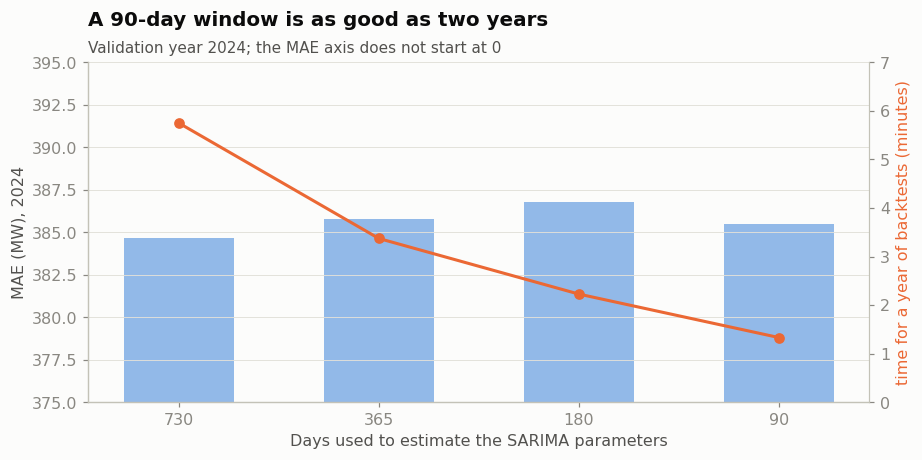

| days for the SARIMA parameters | time (s) | MAE (MW) |
|---|---:|---:|
| 730 | 345 | 384.7 |
| 365 | 202 | 385.8 |
| 180 | 134 | 386.8 |
| 90 | 80 | 385.5 |

In [17]:
w = windows.groupby("sarima_days").agg(runtime=("runtime_s", "first"), MAE=("mae", "mean")).sort_index(ascending=False)
fig, ax = plt.subplots(figsize=(8.5, 4.3))
ax2 = ax.twinx()
ax.bar(w.index.astype(str), w.MAE, color=C["blue"], alpha=0.5, width=0.55)
ax.set_ylim(375, 395); ax.set_ylabel("MAE (MW), 2024")
ax2.plot(w.index.astype(str), w.runtime / 60, color=C["orange"], marker="o"); ax2.set_ylim(0, 7)
ax2.set_ylabel("time for a year of backtests (minutes)", color=C["orange"])
ax2.grid(False); ax2.spines["right"].set_visible(True)
ax.set_xlabel("Days used to estimate the SARIMA parameters")
headline(ax, "A 90-day window is as good as two years", "Validation year 2024; the MAE axis does not start at 0")
plt.tight_layout(); plt.show()
table = w.rename(columns={"MAE": "MAE (MW)", "runtime": "time (s)"})
table.index.name = "days for the SARIMA parameters"
show_md(table.round({"MAE (MW)": 1, "time (s)": 0}), code_index=False)

All four are within about 2 MW of each other, which is inside the noise of one validation year, and 730 days is not even the
best of the shorter ones by much (384.7 MW against 385.5 MW for 90 days). But the 90-day fit makes a year of monthly
refits about four times faster (1.3 against 5.7 minutes). That is the window I use from here on; the regression keeps its 730.

## Step 9: deciding by cross-validation

Now the decision. The cross-validation turns every month of 2022 to 2024 into a fold: 36 times, a month is forecast by a
model fitted on data before it. I compared 15 specifications that differ in the order, in whether there is a plain
difference, and in how many yearly harmonics the regression has. The figure shows each one's MAE and, in
markers, the three years separately.

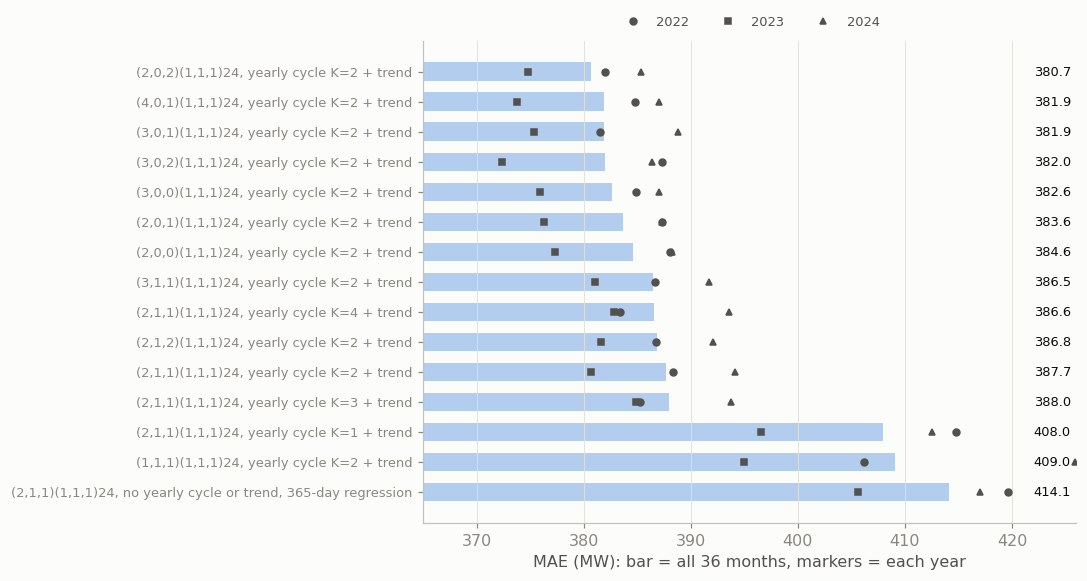

                                                                  MAE   2022   2023   2024  vs (2,1,1)   se
model                                                                                                      
(2,0,2)(1,1,1)24, yearly cycle K=2 + trend                      380.7  382.0  374.8  385.3        -7.0  1.4
(4,0,1)(1,1,1)24, yearly cycle K=2 + trend                      381.9  384.8  373.8  387.0        -5.8  1.7
(3,0,1)(1,1,1)24, yearly cycle K=2 + trend                      381.9  381.5  375.3  388.8        -5.8  1.6
(3,0,2)(1,1,1)24, yearly cycle K=2 + trend                      382.0  387.3  372.4  386.4        -5.7  2.2
(3,0,0)(1,1,1)24, yearly cycle K=2 + trend                      382.6  384.9  376.0  387.0        -5.1  1.5
(2,0,1)(1,1,1)24, yearly cycle K=2 + trend                      383.6  387.3  376.3  387.4        -4.0  2.0
(2,0,0)(1,1,1)24, yearly cycle K=2 + trend                      384.6  388.1  377.3  388.3        -3.1  2.0
(3,1,1)(1,1,1)24, yearly cyc

In [18]:
cvm = cv.assign(year=cv.month.str[:4])
tab = cvm.groupby("model").apply(lambda d: pd.Series({"MAE": np.average(d.mae, weights=d.n),
                                                      **{y_: np.average(g.mae, weights=g.n) for y_, g in d.groupby("year")}}))
tab = tab.sort_values("MAE")
ref = "(2,1,1)(1,1,1)24, yearly cycle K=2 + trend"
paired = cvm.pivot(index="month", columns="model", values="mae")
d_ref = paired.sub(paired[ref], axis=0)
tab["vs (2,1,1)"] = d_ref.mean().reindex(tab.index)
tab["se"] = (d_ref.std() / np.sqrt(len(d_ref))).reindex(tab.index)

fig, ax = plt.subplots(figsize=(10, 5.4))
plot = tab.iloc[::-1]
ax.barh(plot.index, plot.MAE, color=C["blue"], alpha=0.35, height=0.62)
for i, (_, row) in enumerate(plot.iterrows()):
    for yr, mk in zip(["2022", "2023", "2024"], ["o", "s", "^"]):
        ax.plot(row[yr], i, mk, color=C["ink2"], ms=4.5, label=yr if i == 0 else None)
    ax.text(425.5, i, f"{row.MAE:.1f}", va="center", ha="right", fontsize=8.5)
ax.set_xlim(365, 426)
ax.set_xlabel("MAE (MW): bar = all 36 months, markers = each year"); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8.5)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, fontsize=8.5)
plt.tight_layout(); plt.show()
print(tab.round(1).to_string())

- **No plain difference wins.** Every `d = 0` model (380.7 to 384.6 MW) beats every `d = 1` model, and the best,
  (2,0,2)(1,1,1), is **7.0 ± 1.4 MW** ahead of the (2,1,1) I started with (paired differences by month, mean ± standard
  error). This agrees with the stationarity tests of step 4.
- **Two yearly harmonics are enough.** One is 20.3 ± 2.8 MW worse, three or four gain nothing (+0.3 ± 1.3 and
  −1.1 ± 1.3 MW). Dropping the yearly cycle, the trend and the long window costs 26 MW (414.1 against 387.7).
- **Among the `d = 0` models the differences are inside the noise** (380.7, 381.9, 381.9, 382.0 MW), so I took the nominal
  winner, (2,0,2)(1,1,1), and not the one the information criteria liked.

The final specification, frozen before looking at 2025: a regression on weather, calendar, two yearly harmonics and a
trend over the previous 730 days, with **SARIMA(2,0,2)(1,1,1)₂₄** on its residuals, parameters estimated on the last 90
days and refreshed every month.

## The final exam: 2025, and a holdout nobody has tuned on

Now the part that matters. The frozen specification was run once on 2025, and then on January to September 2026.

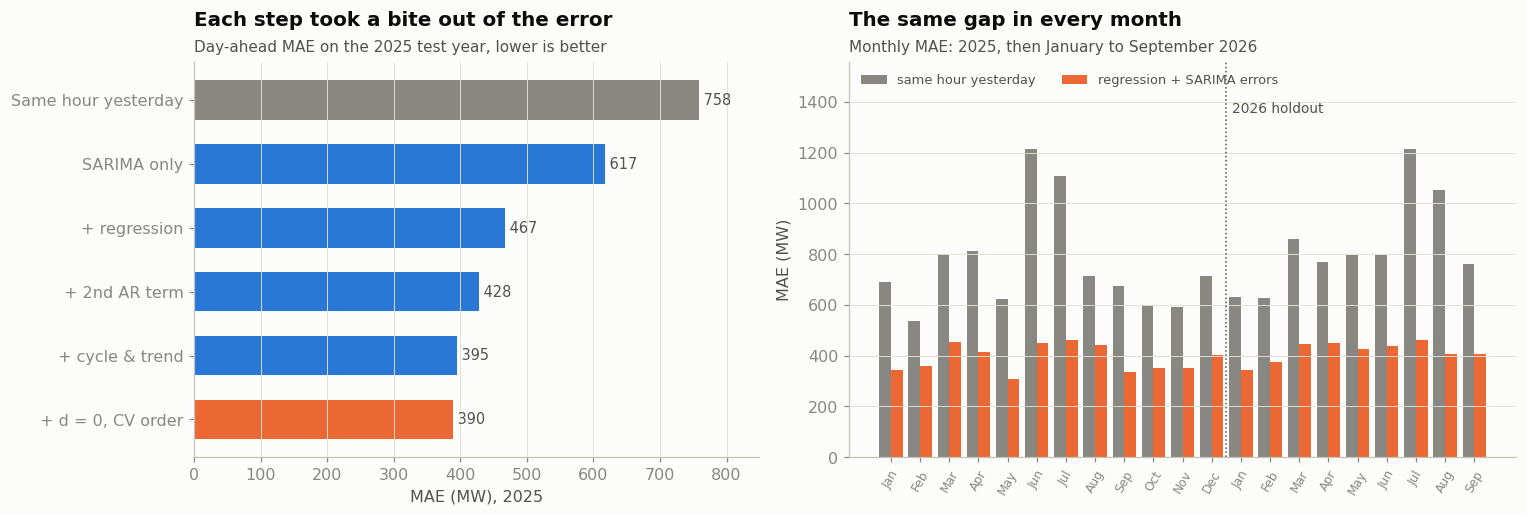

2025: model 389.5 MW (2.34% of the mean demand), same hour yesterday 758.0 MW, skill 48.6%
previous specification (2,1,1): 2025 398.7 MW, 2026 holdout 419.0 MW
2026 holdout: model 417.2 MW, same hour yesterday 838.5 MW, skill 50.2%


In [19]:
ladder = [("Same hour yesterday", "naive_day"), ("SARIMA only", "sarima"), ("+ regression", "sarimax_first"),
          ("+ 2nd AR term", "sarimax_second_ar"), ("+ cycle & trend", "sarimax_yearly_trend"),
          ("+ d = 0, CV order", "sarimax_final")]
scores = [(label, mae(run(name))) for label, name in ladder]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.1, 1.3]})
ax = axes[0]
labels, vals = zip(*scores[::-1])
ax.barh(labels, vals, color=[C["orange"] if i == 0 else C["muted"] if i == len(vals) - 1 else C["blue"] for i in range(len(vals))], height=0.62)
for i, v in enumerate(vals):
    ax.text(v, i, f" {v:,.0f}", va="center", fontsize=9.5, color=C["ink2"])
ax.set_xlabel("MAE (MW), 2025"); ax.set_xlim(0, max(vals) * 1.12); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
headline(ax, "Each step took a bite out of the error", "Day-ahead MAE on the 2025 test year, lower is better")
ax = axes[1]
m = lambda name, period: ((run(name, period).forecast - run(name, period).actual).abs().groupby(run(name, period).index.to_period("M")).mean())
final_m = pd.concat([m("sarimax_final", "test 2025"), m("sarimax_final", "holdout 2026")])
naive_m = pd.concat([m("naive_day", "test 2025"), m("naive_day", "holdout 2026")])
x = np.arange(len(final_m))
ax.bar(x - 0.2, naive_m.to_numpy(), width=0.4, color=C["muted"], label="same hour yesterday")
ax.bar(x + 0.2, final_m.to_numpy(), width=0.4, color=C["orange"], label="regression + SARIMA errors")
ax.axvline(11.5, color=C["ink2"], lw=1, ls=":")
ax.set_ylim(0, ax.get_ylim()[1] * 1.22)
ax.text(11.7, ax.get_ylim()[1] * 0.9, "2026 holdout", fontsize=9, color=C["ink2"], va="top")
ax.set_xticks(x, [p.strftime("%b") for p in final_m.index], fontsize=8, rotation=60)
ax.set_ylabel("MAE (MW)"); ax.legend(loc="upper left", fontsize=8.5, ncols=2)
headline(ax, "The same gap in every month", "Monthly MAE: 2025, then January to September 2026")
plt.tight_layout(); plt.show()
t, h = run("sarimax_final"), run("sarimax_final", "holdout 2026")
tn, hn = run("naive_day"), run("naive_day", "holdout 2026")
print(f"2025: model {mae(t):,.1f} MW ({mae(t) / t.actual.mean():.2%} of the mean demand), same hour yesterday {mae(tn):,.1f} MW, "
      f"skill {1 - mae(t) / mae(tn):.1%}")
pt, ph = run("sarimax_prev_90d"), run("sarimax_prev_90d", "holdout 2026")
print(f"previous specification (2,1,1): 2025 {mae(pt):,.1f} MW, 2026 holdout {mae(ph):,.1f} MW")
print(f"2026 holdout: model {mae(h):,.1f} MW, same hour yesterday {mae(hn):,.1f} MW, skill {1 - mae(h) / mae(hn):.1%}")

- **2025: 389.5 MW** (MAPE 2.33%) against 758.0 MW (4.58%) for the same hour yesterday, a saving of **48.6%**.
  The left panel is the whole journey, and every step took a bite: SARIMA alone 617 MW, the regression underneath it
  467, a second AR term 428, the yearly cycle and trend 395, and the cross-validated `d = 0` order 390.
- **2026 holdout: 417.2 MW** (2.46%) against 838.5 MW (4.95%), a saving of **50.2%**. The absolute error is higher than in 2025, but so is
  the baseline's, and the saving is the same, so the model did not degrade on data it had never seen.
- **The gain over the specification before the cross-validation is real but modest:** the previous (2,1,1) scored 398.7 MW
  on 2025 and 419.0 MW on the holdout, so 9.2 MW and 1.8 MW.
- **The gap holds in every month** (right panel), summer and winter, 2025 and 2026.

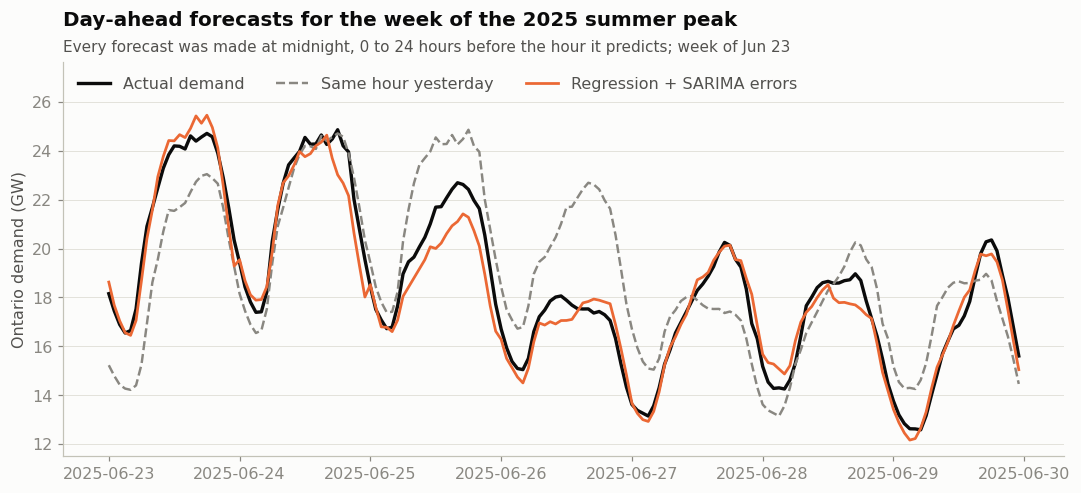

MAE that week: same hour yesterday 1,771 MW, regression + SARIMA errors 544 MW


In [20]:
# The week of the 2025 summer peak: actual demand, "same hour yesterday", and the model of this post.
peak = run("naive_day").actual.loc["2025-06-01":"2025-08-31"].idxmax()
start = peak.normalize() - pd.Timedelta(days=peak.weekday())
week = slice(start, start + pd.Timedelta(hours=167))
fig, ax = plt.subplots()
x = run("naive_day").loc[week].index
ax.plot(x, run("naive_day").loc[week].actual / 1000, color=C["ink"], lw=2.2, label="Actual demand")
ax.plot(x, run("naive_day").loc[week].forecast / 1000, color=C["muted"], lw=1.6, ls="--", label="Same hour yesterday")
ax.plot(x, run("sarimax_final").loc[week].forecast / 1000, color=C["orange"], lw=1.8, label="Regression + SARIMA errors")
ax.set_ylabel("Ontario demand (GW)")
ax.legend(loc="upper left", ncols=3)
ax.set_ylim(top=ax.get_ylim()[1] + 1.5)
headline(ax, "Day-ahead forecasts for the week of the 2025 summer peak",
         f"Every forecast was made at midnight, 0 to 24 hours before the hour it predicts; week of {start:%b %-d}")
plt.tight_layout(); plt.show()
mae = lambda f: (f.forecast - f.actual).abs().mean()
print(f"MAE that week: same hour yesterday {mae(run('naive_day').loc[week]):,.0f} MW, "
      f"regression + SARIMA errors {mae(run('sarimax_final').loc[week]):,.0f} MW")

To see what these errors look like, here is the hardest week of the test year: the week of the 2025 summer peak, a heat
wave. "Same hour yesterday" is a day late whenever the weather moves: it under-forecasts while the heat builds and
over-forecasts when it breaks, and its error that week is **1,771 MW**. The model, a regression plus SARIMA errors,
follows the shape and misses by **544 MW**.

## Where it still fails

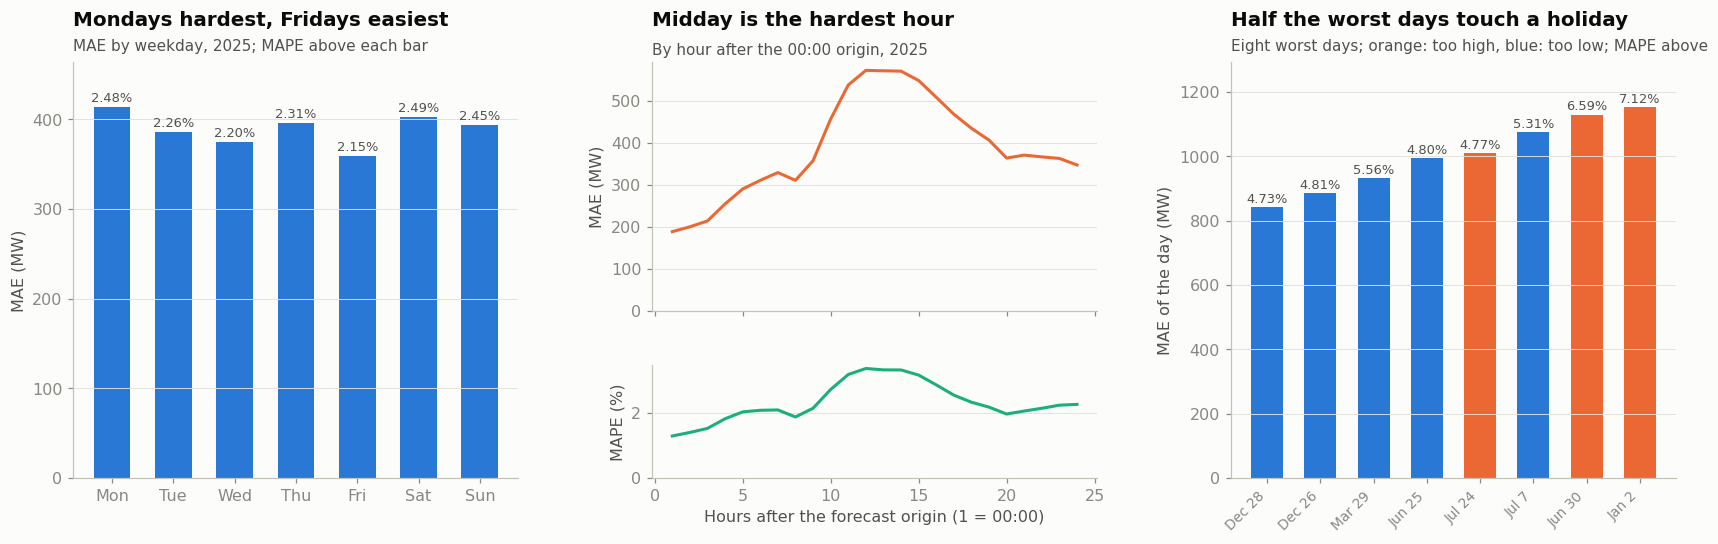

                mae  mape     bias    actual    weekday
day                                                    
2025-01-02  1153.93  7.12  1153.93  16812.88   Thursday
2025-06-30  1130.17  6.59  1130.17  17128.67     Monday
2025-07-07  1075.25  5.31 -1000.48  19605.21     Monday
2025-07-24  1010.82  4.77   765.11  19939.75   Thursday
2025-06-25   994.85  4.80  -976.95  20020.50  Wednesday
2025-03-29   933.44  5.56  -932.84  16193.62   Saturday
2025-12-26   886.67  4.81  -874.62  17656.25     Friday
2025-12-28   842.99  4.73  -842.99  17690.25     Sunday
MAE by hour after the origin: {1: 189.0, 6: 311.0, 12: 573.0, 14: 571.0, 18: 435.0, 24: 348.0}
MAPE by hour after the origin: {1: 1.29, 6: 2.09, 12: 3.37, 14: 3.33, 18: 2.33, 24: 2.27}
MAE by weekday: {'Mon': 414.0, 'Tue': 386.0, 'Wed': 375.0, 'Thu': 396.0, 'Fri': 360.0, 'Sat': 403.0, 'Sun': 394.0}
MAPE by weekday: {'Mon': 2.48, 'Tue': 2.26, 'Wed': 2.2, 'Thu': 2.31, 'Fri': 2.15, 'Sat': 2.49, 'Sun': 2.45}


In [21]:
f = run("sarimax_final").copy()
f["abs_err"] = (f.forecast - f.actual).abs()
f["pct_err"] = f.abs_err / f.actual * 100
f["day"] = f.index.normalize()
daily_err = f.groupby("day").agg(mae=("abs_err", "mean"), mape=("pct_err", "mean"), bias=("forecast", "mean"), actual=("actual", "mean"))
daily_err["bias"] = daily_err.bias - daily_err.actual
worst = daily_err.sort_values("mae", ascending=False).head(8)
by_weekday = f.groupby(f.index.dayofweek)[["abs_err", "pct_err"]].mean()
by_horizon = f.groupby("horizon")[["abs_err", "pct_err"]].mean()


def label_bars(ax, bars, values, pad):
    for b_, v in zip(bars, values):
        ax.text(b_.get_x() + b_.get_width() / 2, b_.get_height() + pad, f"{v:.2f}%", ha="center", fontsize=8.5, color=C["ink2"])


fig = plt.figure(figsize=(15.5, 5.4))
gs = fig.add_gridspec(2, 3, height_ratios=[2.2, 1], hspace=0.3, wspace=0.3, left=0.05, right=0.99, top=0.84, bottom=0.14)
ax = fig.add_subplot(gs[:, 0])
bars = ax.bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], by_weekday.abs_err.to_numpy(), color=C["blue"], width=0.6)
label_bars(ax, bars, by_weekday.pct_err.to_numpy(), 6)
ax.set_ylabel("MAE (MW)"); ax.set_ylim(0, by_weekday.abs_err.max() * 1.12)
headline(ax, "Mondays hardest, Fridays easiest", "MAE by weekday, 2025; MAPE above each bar")
ax = fig.add_subplot(gs[0, 1])
ax.plot(by_horizon.index, by_horizon.abs_err.to_numpy(), color=C["orange"])
ax.set_ylim(bottom=0); ax.set_ylabel("MAE (MW)"); ax.tick_params(labelbottom=False)
headline(ax, "Midday is the hardest hour", "By hour after the 00:00 origin, 2025")
ax = fig.add_subplot(gs[1, 1], sharex=ax)
ax.plot(by_horizon.index, by_horizon.pct_err.to_numpy(), color=C["aqua"])
ax.set_ylim(bottom=0); ax.set_ylabel("MAPE (%)"); ax.set_xlabel("Hours after the forecast origin (1 = 00:00)")
ax = fig.add_subplot(gs[:, 2])
labels = [f"{d:%b %-d}" for d in worst.index][::-1]
bars = ax.bar(labels, worst.mae.to_numpy()[::-1], color=[C["orange"] if b > 0 else C["blue"] for b in worst.bias.to_numpy()[::-1]], width=0.6)
label_bars(ax, bars, worst.mape.to_numpy()[::-1], 14)
ax.set_ylim(0, worst.mae.max() * 1.12)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", fontsize=9)
ax.set_ylabel("MAE of the day (MW)")
headline(ax, "Half the worst days touch a holiday", "Eight worst days; orange: too high, blue: too low; MAPE above")
plt.show()
print(worst.assign(weekday=worst.index.day_name()).round(2).to_string())
print("MAE by hour after the origin:", by_horizon.abs_err.loc[[1, 6, 12, 14, 18, 24]].round(0).to_dict())
print("MAPE by hour after the origin:", by_horizon.pct_err.loc[[1, 6, 12, 14, 18, 24]].round(2).to_dict())
print("MAE by weekday:", dict(zip(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], by_weekday.abs_err.round(0))))
print("MAPE by weekday:", dict(zip(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], by_weekday.pct_err.round(2))))

- **By weekday, Mondays are the hardest (414 MW) and Fridays the easiest (360 MW).** A Monday follows a weekend, and the same
  hour yesterday is a poor guide to it. In percentages the weekend is as hard (MAPE 2.49% on Saturday, 2.48% on Monday, 2.15% on
  Friday), because weekend demand is lower, so the same MW error is a bigger share.
- **By hour, the middle of the day is the hardest.** Because every forecast is made at midnight, the horizon is also the
  hour of the day: the error is 189 MW in the first hour, when the model still remembers last night, climbs to about
  570 MW around noon and 2 p.m. (MAPE 1.29% in the first hour, 3.37% around noon), when, I'd guess, air conditioning and the office day set the level, and is 348 MW at the end of the
  day.
- **Four of the eight worst days sit next to a holiday.** January 2 (the Thursday after New Year's Day) and Monday June 30
  (the day before Canada Day) were over-forecast by about 1.1 GW (MAPE 7.1% and 6.6%), because many people took the day off; Boxing Day and the
  Sunday after Christmas were under-forecast by about 0.9 GW. A holiday flag cannot know about *bridge days*. The other
  four (June 25, July 7, July 24 and a Saturday in March) I cannot explain from weather and calendar alone.

## The recipe, and what comes next

| Step | The question | What I found | The decision |
|---|---|---|---|
| 1. Regression | Do weather and calendar explain demand? | R² 0.89; every block significant (robust tests) | keep it |
| 2. Residuals | Are the errors noise? | autocorrelation 0.92 at 1 h, Durbin-Watson 0.15 | model them with SARIMA |
| 3. Yearly cycle, trend | What slow part is left? | ±1 GW cycle, +204 MW per year; sd 754 → 624 MW | add both, learn from 730 days |
| 4. Stationarity | Difference? | tests agree only after step 3 | `d = 0`, `D = 1` |
| 5. ACF and PACF | Which terms? | AR(2), seasonal MA(1) | start at (2,0,0)(0,1,1) |
| 6. AIC and BIC | Which order? | a seasonal AR also pays, then small gains | a shortlist, not a verdict |
| 7. One backtest month | How is the forecast made? | refit monthly, roll the filter daily | no leakage |
| 8. Cross-validation | Which specification? | `d = 0` by 7.0 ± 1.4 MW; two harmonics | (2,0,2)(1,1,1), 90-day SARIMA window |

**What this baseline cannot do.** It uses the weather that actually happened. A real forecast has to use *forecast* weather,
which is worse, so the next step is to repeat the evaluation with archived weather forecasts. It also knows holidays
only as a yes or a no, so bridge days and the days around holidays are the clearest place to improve. And a point forecast
says nothing about how wrong it might be, which is what the probabilistic work after this needs.

A first gradient-boosting model on the same backtest, same observed weather, reaches about 300 MW. A regression with SARIMA
errors will not win on accuracy; its job is to be a transparent baseline, one whose every term can be read, tested and
explained.

All the code is in the notebook linked at the top of this page, and the backtest results it reads are in its `data` folder.